In [1]:
# Le notebook s'execute depuis notebooks/ : on ajoute la racine du projet
# au sys.path pour que "from src... import ..." fonctionne.
import sys
from pathlib import Path

RACINE = Path.cwd().parent
sys.path.insert(0, str(RACINE))

# les deux fichiers de logs du projet
FICHIERS = [str(RACINE / "data" / "serveur1.log"),
            str(RACINE / "data" / "serveur2.log")]

# Rapport : moteur d'analyse de flux de logs

Projet final de Python, ING3, ECE Paris. Nawel, Basma, Joseph.

Ce projet est un outil en ligne de commande qui analyse des fichiers de logs
système et réseau. Il lit les fichiers ligne par ligne, sans jamais les charger
entièrement en mémoire, puis il nettoie les données, calcule des statistiques et
détecte les comportements suspects.

Ce notebook importe les fonctions du dossier `src/` : aucune logique n'est
recopiée ici. Les cellules appellent le moteur et mettent ses résultats en forme.

In [2]:
import inspect
import tempfile
import tracemalloc

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

from src.analyse import analyser_logs, comparer_blacklist, detecter_force_brute
from src.analyse import charger_blacklist
from src.audit import exporter_audit
from src.filtres import construire_pipeline, creer_compteurs, normaliser_log, router_log
from src.logs import creer_fichier_test, lire_fichier, lire_plusieurs_fichiers
from src.regles import apply_security_rules, regle_blacklist
from src.regles import regle_force_brute, regle_trop_de_critiques
from src.transfo import parser_ligne

# une couleur par serie, axes et grille discrets
BLEU = "#2a78d6"
ORANGE = "#eb6834"
ENCRE = "#52514e"
GRILLE = "#e4e3df"

plt.rcParams.update({
    "figure.figsize": (7, 3.8), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRILLE, "axes.labelcolor": ENCRE,
    "axes.titleweight": "bold", "grid.color": GRILLE,
    "xtick.color": ENCRE, "ytick.color": ENCRE,
    "xtick.bottom": False, "ytick.left": False, "xtick.labelsize": 8.5,
})

## 1. Objectif et architecture

**Objectif** : traiter des fichiers de logs sans que la mémoire utilisée dépende
de leur taille, tout en détectant deux comportements suspects :

- les adresses IP présentes dans une liste noire (blacklist) ;
- les attaques par force brute (plusieurs échecs de connexion consécutifs
  depuis la même IP).

Chaque ligne traverse les étapes suivantes, une par une :

```
fichiers .log
  -> lecture (yield / yield from)            src/logs.py
  -> ligne -> dictionnaire + tuple           src/transfo.py
  -> nettoyage et filtrage (filter / map)    src/filtres.py
  -> statistiques et détection               src/analyse.py
  -> règles de sécurité                      src/regles.py
  -> affichage et audit                      main.py, src/audit.py
```

| Module | Fichiers | Rôle |
|---|---|---|
| 1 | `src/logs.py`, `src/transfo.py` | lecture par générateurs, parsing en dictionnaires et tuples |
| 2 | `src/filtres.py` | filtrage (`filter`, `lambda`), transformation (`map`), routage (`match-case`) |
| 3 | `src/analyse.py` | ensembles, `defaultdict`, détection de force brute |
| 4 | `src/regles.py`, `src/audit.py` | moteur de règles `*args` / `**kwargs`, audit `globals()` / `locals()` |
| - | `main.py` | enchaînement des étapes et affichage des résultats |

## 2. Module 1 : générateurs et paresse

`lire_fichier` est un générateur : il renvoie les lignes une par une avec
`yield`. `next()` demande une seule ligne, le reste du fichier n'est pas lu.

In [3]:
flux = lire_fichier(FICHIERS[0])
print("Type :", type(flux))
# la premiere ligne du fichier est vide (cas de test)
print("1re ligne :", repr(next(flux)))
print("2e ligne  :", next(flux))
# on ferme le generateur, donc aussi le fichier
flux.close()

Type : <class 'generator'>
1re ligne : ''
2e ligne  : 2026-11-03T09:00:07 | INFO | 10.0.0.5:22/TCP | user=david | {"event": "login_success"}


`lire_plusieurs_fichiers` enchaîne plusieurs fichiers avec `yield from`.
Le résultat est lui aussi un générateur.

In [4]:
flux = lire_plusieurs_fichiers(FICHIERS)
print("Type :", type(flux))
# on compte en parcourant : une seule ligne en memoire a la fois
print("Lignes lues dans les 2 fichiers :", sum(1 for _ in flux))

Type : <class 'generator'>
Lignes lues dans les 2 fichiers : 2022


Preuve de paresse sur le pipeline complet : les compteurs restent à zéro tant
qu'aucun log n'est demandé.

In [5]:
compteurs = creer_compteurs()
logs = construire_pipeline(lire_plusieurs_fichiers(FICHIERS), compteurs)
print("Pipeline construit : lignes lues =", compteurs["lues"])
premier = next(logs)
print("Apres un next()    : lignes lues =", compteurs["lues"])
print("Premier log :", premier["resume"])

Pipeline construit : lignes lues = 0
Apres un next()    : lignes lues = 2
Premier log : [09:00:07] INFO            10.0.0.5:22 TCP user=david


`parser_ligne` transforme une ligne de texte en dictionnaire. La connexion
devient un tuple `(IP, Port, Protocole)`.

In [6]:
flux = lire_fichier(FICHIERS[0])
next(flux)  # on saute la ligne vide
ligne = next(flux)
flux.close()

print("AVANT :", ligne)
print()
print("APRES :")
log = parser_ligne(ligne)
for cle, valeur in log.items():
    print(f"  {cle:<10} {valeur!r}")
print()
print("Type de la connexion :", type(log["connexion"]))

AVANT : 2026-11-03T09:00:07 | INFO | 10.0.0.5:22/TCP | user=david | {"event": "login_success"}

APRES :
  date       datetime.datetime(2026, 11, 3, 9, 0, 7)
  niveau     'INFO'
  ip         '10.0.0.5'
  connexion  ('10.0.0.5', 22, 'TCP')
  user       'david'
  message    {'event': 'login_success'}

Type de la connexion : <class 'tuple'>


## 3. Module 2 : `filter`, `map`, `lambda` et routage `match-case`

`construire_pipeline` enchaîne `filter()` et `map()`. Ces fonctions renvoient
des itérateurs : rien n'est calculé tant qu'on ne parcourt pas le résultat.

In [7]:
logs = construire_pipeline(lire_plusieurs_fichiers(FICHIERS))
print("Type :", type(logs))
print("1er log valide :", next(logs)["resume"])

Type : <class 'map'>
1er log valide : [09:00:07] INFO            10.0.0.5:22 TCP user=david


Une ligne sale, avant et après `normaliser_log` : le niveau passe en
majuscules, l'utilisateur et le message texte sont remis en forme. Ensuite, un
petit jeu de lignes montre ce que le pipeline retire : `filter(None, ...)`
enlève les lignes vides.

In [8]:
ligne_sale = ("2026-11-03T09:50:26 | warning | 10.0.0.5:80/TCP "
              "| user=ALICE |   Disk Usage HIGH  ")
brut = parser_ligne(ligne_sale)
propre = normaliser_log(brut)

for cle in ("niveau", "user", "message"):
    print(f"{cle:<8} avant : {brut[cle]!r:<24} apres : {propre[cle]!r}")
print("Resume :", propre["resume"])
print()

lignes_test = ["", ligne_sale, "ligne cassee", ""]
logs_test = list(construire_pipeline(lignes_test))
print(f"{len(lignes_test)} lignes en entree -> {len(logs_test)} log valide")

niveau   avant : 'warning'                apres : 'WARNING'
user     avant : 'ALICE'                  apres : 'alice'
message  avant : '  Disk Usage HIGH  '    apres : 'disk usage high'
Resume : [09:50:26] WARNING         10.0.0.5:80 TCP user=alice

4 lignes en entree -> 1 log valide


Le pipeline compte aussi ce qu'il rejette. Les compteurs ne sont remplis
qu'au moment où l'on parcourt les logs, car le pipeline est paresseux.

In [9]:
compteurs = creer_compteurs()
logs = construire_pipeline(lire_plusieurs_fichiers(FICHIERS), compteurs)
print("Avant le parcours :", compteurs)

nb_valides = sum(1 for _ in logs)
print("Apres le parcours :", compteurs)
print("Logs valides      :", nb_valides)

total = (compteurs["vides"] + compteurs["fausses"]
         + compteurs["invalides"] + nb_valides)
print("lues = vides + fausses + invalides + valides :",
      compteurs["lues"] == total)

Avant le parcours : {'lues': 0, 'vides': 0, 'fausses': 0, 'invalides': 0}
Apres le parcours : {'lues': 2022, 'vides': 100, 'fausses': 2, 'invalides': 2}
Logs valides      : 1918
lues = vides + fausses + invalides + valides : True


`router_log` utilise `match-case` : la catégorie dépend de la forme de
l'élément reçu (chaîne, dictionnaire ou tuple).

In [10]:
exemples = [
    "disk usage high",
    {"niveau": "INFO", "message": {"event": "login_failed"}},
    {"niveau": "CRITICAL", "message": "disk usage high"},
    {"event": "logout"},
    ("10.0.0.5", 22, "TCP"),
    ("10.0.0.5", 443, "TCP"),
    ("10.0.0.5", 53, "UDP"),
    42,
]
for element in exemples:
    print(f"{type(element).__name__:<6} {router_log(element):<18} {element}")

str    texte_brut         disk usage high
dict   echec_connexion    {'niveau': 'INFO', 'message': {'event': 'login_failed'}}
dict   erreur             {'niveau': 'CRITICAL', 'message': 'disk usage high'}
dict   logout             {'event': 'logout'}
tuple  ssh                ('10.0.0.5', 22, 'TCP')
tuple  web                ('10.0.0.5', 443, 'TCP')
tuple  udp                ('10.0.0.5', 53, 'UDP')
int    inconnu            42


Table de routage : une passe sur les logs du projet, avec un exemple par
catégorie.

In [11]:
exemple_par_categorie = {}
nombre_par_categorie = {}
for log in construire_pipeline(lire_plusieurs_fichiers(FICHIERS)):
    categorie = router_log(log)
    exemple_par_categorie.setdefault(categorie, log["resume"])
    nombre_par_categorie[categorie] = nombre_par_categorie.get(categorie, 0) + 1

print(f"{'Categorie':<18} {'Logs':>5}  Exemple")
for categorie in sorted(nombre_par_categorie, key=nombre_par_categorie.get,
                        reverse=True):
    print(f"{categorie:<18} {nombre_par_categorie[categorie]:>5}  "
          f"{exemple_par_categorie[categorie]}")

Categorie           Logs  Exemple
connexion_reussie    867  [09:00:07] INFO            10.0.0.5:22 TCP user=david
normal               556  [09:00:11] INFO        192.168.1.10:53 UDP user=alice
erreur               252  [09:00:44] CRITICAL    192.168.1.11:443 TCP user=eve
echec_connexion      243  [09:00:21] WARNING     192.168.1.11:53 UDP user=alice


Le code de `router_log`, lu directement dans `src/filtres.py` : chaque `case`
décrit une forme possible de l'élément.

In [12]:
print(inspect.getsource(router_log).strip())

def router_log(element: object) -> str:
    """Donne une categorie a un element selon sa forme (match-case)."""
    # on compare la forme de element a chaque "case", dans l'ordre
    match element:
        # une chaine de texte
        case str():
            return "texte_brut"
        # un tuple dont le 2e element vaut 22 et le 3e "TCP"
        # ("_" veut dire : n'importe quelle valeur)
        case (_, 22, "TCP"):
            return "ssh"
        # un tuple avec le port 80 OU 443 en TCP
        case (_, 80 | 443, "TCP"):
            return "web"
        # un tuple avec n'importe quel port en UDP
        case (_, _, "UDP"):
            return "udp"
        # un dict dont le message est un echec de connexion
        case {"message": {"event": "login_failed"}}:
            return "echec_connexion"
        # un dict dont le message est une connexion reussie
        case {"message": {"event": "login_success"}}:
            return "connexion_reussie"
        # un dict avec un niveau grav

## 4. Module 3 : ensembles, `defaultdict` et détection de force brute

`analyser_logs` parcourt les logs une seule fois et on réutilise son résultat
dans la suite du notebook.

La blacklist est lue dans `data/blacklist.txt` par `charger_blacklist`. C'est un `frozenset` : elle ne peut pas être modifiée.
On la compare aux IP des logs avec les quatre opérateurs d'ensembles :
`&` intersection, `-` différence, `^` différence symétrique, `|` union.

In [13]:
stats = analyser_logs(construire_pipeline(lire_plusieurs_fichiers(FICHIERS)))
blacklist = charger_blacklist(str(RACINE / "data" / "blacklist.txt"))

print("Logs valides :", stats["nb_logs"])
print("Type de la blacklist :", type(blacklist))
print("Blacklist :", sorted(blacklist))
try:
    blacklist.add("1.2.3.4")
except AttributeError as erreur:
    print("Modification refusee :", erreur)
print()

ensembles = comparer_blacklist(stats["ips_actives"], stats["ips_erreur"],
                               blacklist)
operateurs = {"blacklistees_actives": "&", "autorisees": "-",
              "blacklistees_absentes": "-", "difference_symetrique": "^",
              "a_surveiller": "|"}
for nom, ips in ensembles.items():
    print(f"{operateurs[nom]}  {nom:<22} {len(ips)} IP : {sorted(ips)}")

Logs valides : 1918
Type de la blacklist : <class 'frozenset'>
Blacklist : ['192.0.2.66', '192.0.2.99', '203.0.113.42']
Modification refusee : 'frozenset' object has no attribute 'add'

&  blacklistees_actives   2 IP : ['192.0.2.66', '203.0.113.42']
-  autorisees             5 IP : ['10.0.0.5', '172.16.0.3', '192.168.1.10', '192.168.1.11', '198.51.100.7']
-  blacklistees_absentes  1 IP : ['192.0.2.99']
^  difference_symetrique  6 IP : ['10.0.0.5', '172.16.0.3', '192.0.2.99', '192.168.1.10', '192.168.1.11', '198.51.100.7']
|  a_surveiller           7 IP : ['10.0.0.5', '172.16.0.3', '192.0.2.66', '192.0.2.99', '192.168.1.10', '192.168.1.11', '203.0.113.42']


Les compteurs sont des `defaultdict` : une clé absente vaut 0, donc `+= 1` ne
provoque pas d'erreur.

In [14]:
print("Type des compteurs :", type(stats["par_niveau"]))
print("Par niveau     :", dict(stats["par_niveau"]))
print("Par categorie  :", dict(stats["par_categorie"]))
print("Par connexion  :", dict(stats["par_connexion"]))
print("Par utilisateur:", dict(stats["par_user"]))
ip, liste = next(iter(stats["tentatives"].items()))
print(f"tentatives['{ip}'] (defaultdict de listes) :", liste[:2], "...")
print()

# statistiques neuves : lire une cle absente l'ajouterait au dictionnaire
vide = analyser_logs([])
print("Cle absente, aucune KeyError :", vide["par_niveau"]["DEBUG"],
      vide["tentatives"]["0.0.0.0"])

Type des compteurs : <class 'collections.defaultdict'>
Par niveau     : {'INFO': 981, 'WARNING': 330, 'CRITICAL': 293, 'ERROR': 314}
Par categorie  : {'connexion_reussie': 867, 'normal': 556, 'echec_connexion': 243, 'erreur': 252}
Par connexion  : {'ssh': 472, 'udp': 491, 'web': 955}
Par utilisateur: {'david': 380, 'alice': 385, 'charlie': 389, 'bob': 390, 'eve': 365, 'admin': 6, 'visiteur': 3}
tentatives['10.0.0.5'] (defaultdict de listes) : [(datetime.datetime(2026, 11, 3, 9, 0, 7), 'login_success'), (datetime.datetime(2026, 11, 3, 9, 1, 21), 'login_success')] ...

Cle absente, aucune KeyError : 0 []


`detecter_force_brute` cherche au moins 5 échecs consécutifs depuis la même IP,
le premier et le dernier étant espacés de 60 secondes au maximum. Une connexion
réussie remet le compteur à zéro.

In [15]:
force_brute = detecter_force_brute(stats["tentatives"], 5)

for ip in sorted(force_brute):
    if force_brute[ip]["attaque"]:
        etat = "ATTAQUE"
    else:
        etat = "ok"
    print(f"{ip:<15} {etat:<8} max d'echecs d'affilee : "
          f"{force_brute[ip]['max_echecs']}")

10.0.0.5        ok       max d'echecs d'affilee : 3
172.16.0.3      ok       max d'echecs d'affilee : 3
192.168.1.10    ok       max d'echecs d'affilee : 3
192.168.1.11    ok       max d'echecs d'affilee : 3
198.51.100.7    ok       max d'echecs d'affilee : 4
203.0.113.42    ATTAQUE  max d'echecs d'affilee : 5


## 5. Module 4 : `apply_security_rules(*regles, **config)` et audit

`apply_security_rules` reçoit un nombre variable de règles (`*regles`, le
`*args` du sujet) et tous les paramètres nommés dont elles ont besoin
(`**config`, le `**kwargs` du sujet).

In [16]:
print("Aucune regle :")
print(" ", apply_security_rules())

print("Une regle :")
print(" ", apply_security_rules(regle_blacklist, ensembles=ensembles))

print("Trois regles et tous les parametres :")
alertes = apply_security_rules(regle_blacklist, regle_force_brute,
                               regle_trop_de_critiques, stats=stats,
                               ensembles=ensembles, force_brute=force_brute,
                               seuil_critiques=100)
for nom, liste in alertes.items():
    print(" ", nom, ":", liste)

print("Autre seuil (500) :")
print(" ", apply_security_rules(regle_trop_de_critiques, stats=stats,
                                seuil_critiques=500))

print("Parametre manquant :")
print(" ", apply_security_rules(regle_force_brute))

print("Quelque chose qui n'est pas une fonction :")
print(" ", apply_security_rules("coucou", ensembles=ensembles))

Aucune regle :
  {}
Une regle :
  {'regle_blacklist': ['IP blacklistee active : 192.0.2.66', 'IP blacklistee active : 203.0.113.42']}
Trois regles et tous les parametres :
  regle_blacklist : ['IP blacklistee active : 192.0.2.66', 'IP blacklistee active : 203.0.113.42']
  regle_force_brute : ['Force brute depuis 203.0.113.42 a 09:50:00']
  regle_trop_de_critiques : ['293 logs CRITICAL (seuil : 100)']
Autre seuil (500) :
  {'regle_trop_de_critiques': []}
Parametre manquant :
Regle regle_force_brute ignoree : il manque 'force_brute'
  {}
Quelque chose qui n'est pas une fonction :
Ignore (ce n'est pas une fonction) : coucou
  {}


`exporter_audit` écrit un rapport à partir de `globals()` et `locals()`.
Comme le rapport complet est long, on n'en affiche qu'un extrait.

In [17]:
def exemple_audit(destination):
    """Lance l'audit depuis une fonction, pour avoir des variables locales."""
    seuil_exemple = 5
    ip_exemple = "203.0.113.42"
    exporter_audit(destination, globals(), locals())


with tempfile.TemporaryDirectory() as dossier:
    fichier_audit = str(Path(dossier) / "audit.txt")
    exemple_audit(fichier_audit)
    with open(fichier_audit, encoding="utf-8") as fichier:
        rapport = fichier.read().splitlines()

a_montrer = ("===", "apply_security_rules", "blacklist ", "exemple_audit",
             "ip_exemple", "seuil_exemple", "stats ")
for ligne_rapport in rapport:
    if ligne_rapport.startswith(a_montrer):
        print(ligne_rapport)

=== VARIABLES GLOBALES (globals()) ===
apply_security_rules      function        <function apply_security_rules at 0x000001DCCBEBE7A0>
blacklist                 frozenset       frozenset({'192.0.2.66', '192.0.2.99', '203.0.113.42'})
exemple_audit             function        <function exemple_audit at 0x000001DCCBEBECA0>
stats                     dict            {'nb_logs': 1918, 'par_niveau': defaultdict(<class 'int'>, {...
=== VARIABLES LOCALES (locals()) ===
ip_exemple                str             '203.0.113.42'
seuil_exemple             int             5


## 6. Graphiques

Une couleur par série, valeurs étiquetées directement, aucune double échelle.

In [18]:
def tracer_barres(etiquettes, valeurs, titre, nom_x, nom_y, seuil=None):
    """Trace des barres simples, avec la valeur au-dessus de chaque barre."""
    figure, axe = plt.subplots()
    barres = axe.bar(etiquettes, valeurs, color=BLEU, width=0.55)
    axe.bar_label(barres, padding=3, color=ENCRE)
    # ligne horizontale pour reperer un seuil, si on en donne un
    if seuil is not None:
        axe.axhline(seuil, color=ORANGE, linewidth=1.5, linestyle="--")
        axe.text(1.005, seuil, f"seuil = {seuil}", color=ENCRE, va="center",
                 transform=axe.get_yaxis_transform())
    axe.set_title(titre, loc="left")
    axe.set_xlabel(nom_x)
    axe.set_ylabel(nom_y)
    axe.grid(axis="y")
    axe.set_axisbelow(True)
    axe.yaxis.set_major_locator(MaxNLocator(integer=True))
    # un peu de place en haut pour que les valeurs ne touchent pas le titre
    axe.margins(y=0.12)
    plt.tight_layout()
    plt.show()

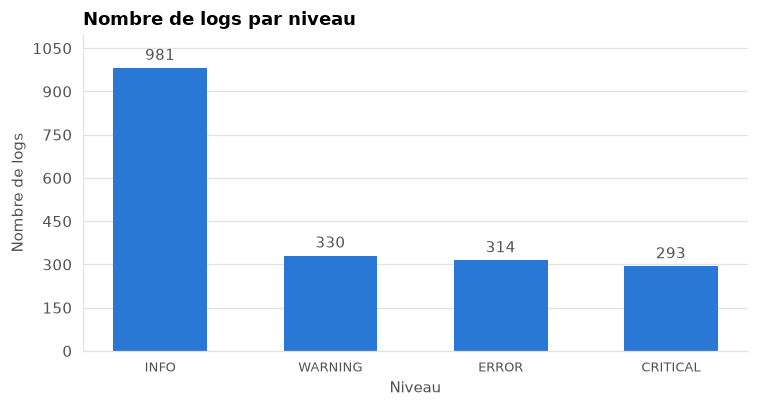

In [19]:
# les niveaux sont ranges du moins grave au plus grave
niveaux = ["INFO", "WARNING", "ERROR", "CRITICAL"]
tracer_barres(niveaux, [stats["par_niveau"][n] for n in niveaux],
              "Nombre de logs par niveau", "Niveau", "Nombre de logs")

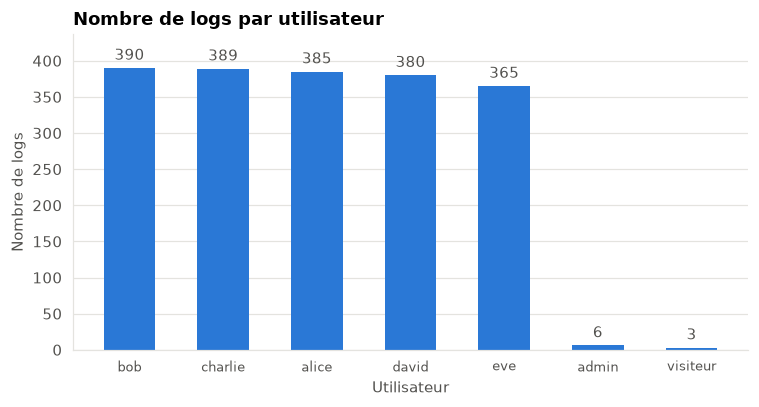

In [20]:
# utilisateurs du plus actif au moins actif
utilisateurs = sorted(stats["par_user"], key=stats["par_user"].get, reverse=True)
tracer_barres(utilisateurs, [stats["par_user"][u] for u in utilisateurs],
              "Nombre de logs par utilisateur", "Utilisateur", "Nombre de logs")

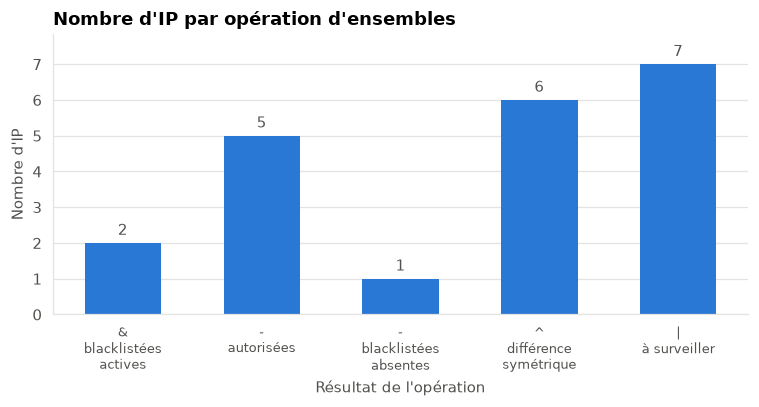

In [21]:
noms = {"blacklistees_actives": "&\nblacklistées\nactives",
        "autorisees": "-\nautorisées",
        "blacklistees_absentes": "-\nblacklistées\nabsentes",
        "difference_symetrique": "^\ndifférence\nsymétrique",
        "a_surveiller": "|\nà surveiller"}
tracer_barres([noms[nom] for nom in ensembles],
              [len(ensembles[nom]) for nom in ensembles],
              "Nombre d'IP par opération d'ensembles",
              "Résultat de l'opération", "Nombre d'IP")

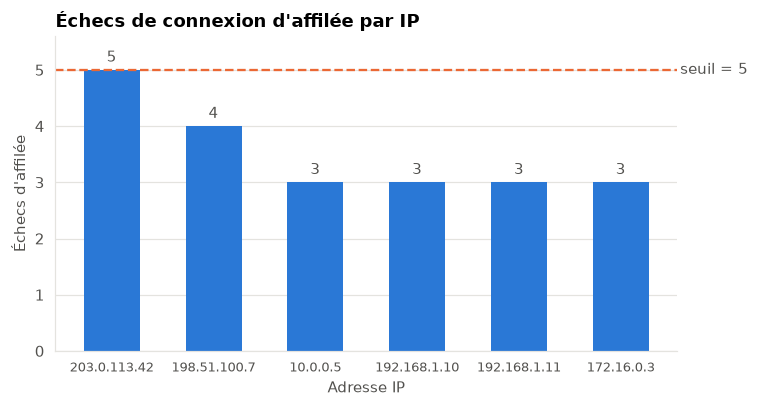

In [22]:
# IP du plus grand au plus petit nombre d'echecs d'affilee
adresses = sorted(force_brute, key=lambda ip: force_brute[ip]["max_echecs"],
                  reverse=True)
tracer_barres(adresses, [force_brute[ip]["max_echecs"] for ip in adresses],
              "Échecs de connexion d'affilée par IP", "Adresse IP",
              "Échecs d'affilée", seuil=5)

## 7. Benchmark mémoire : générateur contre `readlines()`

On crée des fichiers de plus en plus gros dans un dossier temporaire, avec la
fonction `creer_fichier_test` du projet. Pour chaque taille, `tracemalloc`
mesure le pic de mémoire d'une lecture complète, de deux façons :

- avec `lire_fichier` (générateur), en comptant les lignes ;
- avec `open(...).readlines()`, qui charge tout le fichier dans une liste.

In [23]:
TAILLES = [10_000, 50_000, 100_000, 300_000, 500_000]


def lire_avec_generateur(chemin):
    """Parcourt le fichier avec le generateur du projet et compte les lignes."""
    return sum(1 for _ in lire_fichier(chemin))


def lire_avec_readlines(chemin):
    """Charge tout le fichier d'un coup avec readlines()."""
    with open(chemin, encoding="utf-8") as fichier:
        lignes = fichier.readlines()
    return len(lignes)


def pic_memoire(fonction, chemin):
    """Renvoie le nombre de lignes lues et le pic de memoire en Mo."""
    tracemalloc.start()
    nb_lignes = fonction(chemin)
    pic = tracemalloc.get_traced_memory()[1]
    tracemalloc.stop()
    return nb_lignes, pic / 1_000_000


pics_generateur = []
pics_readlines = []
with tempfile.TemporaryDirectory() as dossier:
    for taille in TAILLES:
        chemin = str(Path(dossier) / f"test_{taille}.log")
        creer_fichier_test(chemin, taille, graine=4)
        lignes_g, pic_g = pic_memoire(lire_avec_generateur, chemin)
        lignes_r, pic_r = pic_memoire(lire_avec_readlines, chemin)
        # les deux lectures doivent avoir vu tout le fichier
        assert lignes_g == lignes_r == taille
        pics_generateur.append(pic_g)
        pics_readlines.append(pic_r)

print(f"{'Lignes':>10} {'Generateur (Mo)':>17} {'readlines (Mo)':>16}")
for taille, pic_g, pic_r in zip(TAILLES, pics_generateur, pics_readlines):
    print(f"{taille:>10} {pic_g:>17.3f} {pic_r:>16.1f}")

    Lignes   Generateur (Mo)   readlines (Mo)
     10000             0.035              1.4
     50000             0.035              6.9
    100000             0.035             13.7
    300000             0.035             41.3
    500000             0.035             68.7


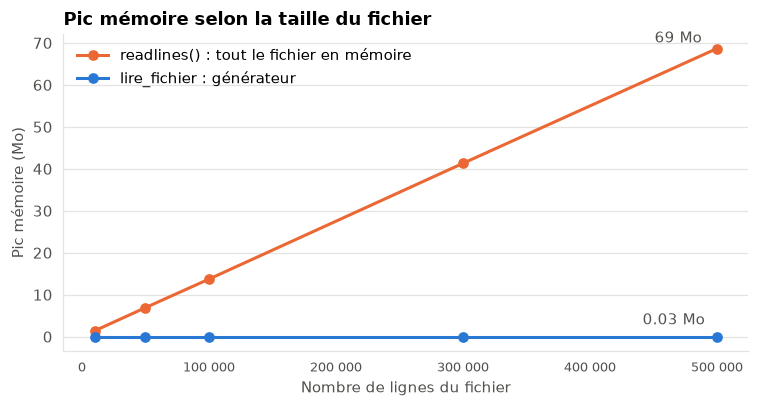

In [24]:
figure, axe = plt.subplots()
axe.plot(TAILLES, pics_readlines, color=ORANGE, marker="o", linewidth=2,
         label="readlines() : tout le fichier en mémoire")
axe.plot(TAILLES, pics_generateur, color=BLEU, marker="o", linewidth=2,
         label="lire_fichier : générateur")
# on ecrit la derniere valeur de chaque courbe directement sur le graphique
axe.annotate(f"{pics_readlines[-1]:.0f} Mo", (TAILLES[-1], pics_readlines[-1]),
             textcoords="offset points", xytext=(-10, 4), ha="right", color=ENCRE)
axe.annotate(f"{pics_generateur[-1]:.2f} Mo", (TAILLES[-1], pics_generateur[-1]),
             textcoords="offset points", xytext=(-8, 8), ha="right", color=ENCRE)
axe.set_title("Pic mémoire selon la taille du fichier", loc="left")
axe.set_xlabel("Nombre de lignes du fichier")
axe.set_ylabel("Pic mémoire (Mo)")
axe.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{int(x):,}".replace(",", " ")))
axe.grid(axis="y")
axe.set_axisbelow(True)
axe.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

**Conclusion.** La courbe du générateur reste plate : `lire_fichier` ne garde
qu'une ligne à la fois en mémoire, quelle que soit la taille du fichier. La
courbe de `readlines()` monte avec le nombre de lignes, car tout le fichier est
chargé dans une liste. C'est pour cette raison que tout le pipeline du projet
reste paresseux.

## 8. Tableau barème → code

| Critère du barème | Notion Python | Fichier | Fonction |
|---|---|---|---|
| Environnement (2) | venv + `requirements.txt` | `requirements.txt` | généré par `pip freeze` |
| Environnement (2) | distinction `.py` / `.ipynb` | `src/`, `notebooks/rapport.ipynb` | moteur et tests en `.py`, rapport en `.ipynb` |
| Mémoire (4) | `yield` | `src/logs.py` | `lire_fichier`, `generer_logs` |
| Mémoire (4) | `yield from` | `src/logs.py` | `lire_plusieurs_fichiers` |
| Structures (4) | dictionnaire | `src/transfo.py` | `parser_ligne` |
| Structures (4) | tuple `(IP, Port, Protocole)` | `src/transfo.py` | `lire_connexion` |
| Structures (4) | `set` | `src/analyse.py` | `analyser_logs` |
| Structures (4) | `frozenset` | `src/analyse.py` | `charger_blacklist`, `comparer_blacklist` |
| Structures (4) | union <code>&#124;</code> | `src/analyse.py` | `comparer_blacklist` |
| Structures (4) | intersection `&` | `src/analyse.py` | `comparer_blacklist` |
| Structures (4) | différence `-` | `src/analyse.py` | `comparer_blacklist` |
| Structures (4) | différence symétrique `^` | `src/analyse.py` | `comparer_blacklist` |
| Structures (4) | `defaultdict` | `src/analyse.py` | `analyser_logs` |
| Structures (4) | `match-case` (str, dict, tuple) | `src/filtres.py` | `router_log` |
| Fonctionnel (4) | `filter(None, ...)` | `src/filtres.py` | `construire_pipeline` |
| Fonctionnel (4) | `filter()` + `lambda` | `src/filtres.py`, `src/analyse.py` | `construire_pipeline`, `charger_blacklist` |
| Fonctionnel (4) | `map()` | `src/filtres.py` | `construire_pipeline` |
| Fonctionnel (4) | f-strings | `src/filtres.py`, `src/logs.py` | `normaliser_log`, `creer_ligne` |
| Fonctionnel (4) | fonctions passées en argument | `src/filtres.py`, `main.py`, `src/regles.py` | `construire_pipeline` (`map(parser_ligne, ...)`), `main` (passe les règles), `apply_security_rules` (les appelle) |
| Règles (3) | `*args` (ici `*regles`) | `src/regles.py` | `apply_security_rules` |
| Règles (3) | `**kwargs` (ici `**config`) | `src/regles.py` | `apply_security_rules` |
| Règles (3) | `globals()`, `locals()` | `main.py`, `src/audit.py` | `main` (appels), `exporter_audit` (écrit le rapport) |
| Qualité (3) | `while` | `src/analyse.py` | `detecter_force_brute` |
| Qualité (3) | `for` | `src/analyse.py` | `detecter_force_brute` |
| Qualité (3) | `break` | `src/analyse.py` | `detecter_force_brute` |
| Qualité (3) | `continue` | `src/analyse.py` | `detecter_force_brute` |
| Qualité (3) | `else` de boucle | `src/analyse.py` | `detecter_force_brute` |
| Qualité (3) | gestion des exceptions | `src/logs.py`, `src/transfo.py`, `src/regles.py` | `lire_fichier`, `lire_message`, `parser_ligne`, `apply_security_rules` |
| Qualité (3) | tests pytest | `tests/test_projet.py`, `pytest.ini` | fonctions `test_...` |

## 9. Limites du projet

- Les niveaux de gravité des logs de test sont tirés au hasard et ne
  correspondent pas toujours aux événements.
- La détection de force brute utilise une fenêtre fixe de 60 secondes : une attaque plus lente, ou répartie entre plusieurs IP, n'est pas détectée.
- Le programme ne lit que le format de ligne décrit dans le README.
- Seules les adresses IPv4 sont acceptées.
- La lecture est paresseuse, mais `analyser_logs` garde en mémoire les ensembles
  d'IP et la liste `tentatives`, qui grandit avec le nombre de connexions.
- `tracemalloc` mesure seulement la mémoire allouée par Python.